In [ ]:
#Assignment 2: Testing data analysis skills with pandas, numpy, and matplotlib. Use the dataset from the zip file.
#Total points: 24

#You are allowed to seek help from your classmates; however, it should be your own work.
#You can not copy or paste their work. If you seek help, you need to acknowledge it in your submission.
#You will submit the commented and outputs-printed Jupyter Notebook file

#Remove all unnecessary code and outputs. 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix #You may or may not need

In [2]:
df = pd.read_csv("used_device_data.csv")

In [7]:
#Question 1: Report any data limitations. Your response must be generated using Python code; do not calculate or analyze this manually. (1 point)
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Missing values by column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData Limitations:")
print("The dataset contains missing values in several columns.")
print("The rear_camera_mp column has the most missing values (179).")
print("There are no duplicate rows.")




device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64
Duplicate rows: 0
Missing values by column:
device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

Duplicate rows: 0

Data Limitations:
The dataset contains m

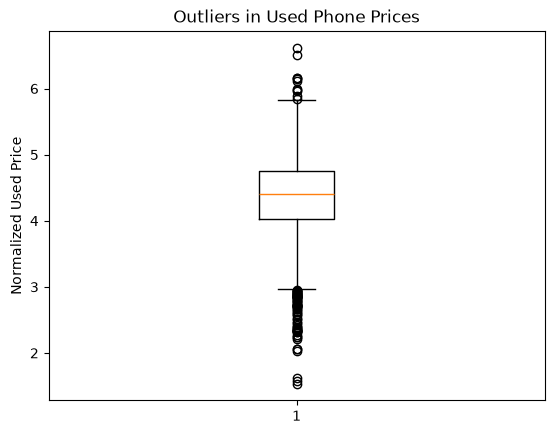

The boxplot shows outliers in normalized used prices.
There are more outliers below the lower whisker than above the upper whisker.
Most prices are concentrated between approximately 4.0 and 4.8.


In [9]:
#Question 2: Comment on outliers using visualization. (2 points)
plt.boxplot(df['normalized_used_price'])
plt.title('Outliers in Used Phone Prices')
plt.ylabel('Normalized Used Price')
plt.show()
print("The boxplot shows outliers in normalized used prices.")
print("There are more outliers below the lower whisker than above the upper whisker.")
print("Most prices are concentrated between approximately 4.0 and 4.8.")

In [21]:
#Question 3: Create a new column device_age that represents the age of the device in years. Print the mean device age. (1 point)



print("Average device age:", df['device_age'].mean())
# I chose this method because it measures how long each device has been used.

Average device age: 1.848958126769836


In [22]:
#Question 4: Now, start using numpy functions to generate insights from the data
#Question 4a: Calculate the average, minimum, and maximum values of days_used using numpy and print them.  (1 point)
print("Average days used:", np.mean(df['days_used']))
print("Minimum days used:", np.min(df['days_used']))
print("Maximum days used:", np.max(df['days_used']))

Average days used: 674.8697162709901
Minimum days used: 91
Maximum days used: 1094


In [24]:
#Question 4b: Calculate and print standard deviation and variance of normalized_used_price. (1 point)
print("Standard deviation:", np.std(df['normalized_used_price']))
print("Variance:", np.var(df['normalized_used_price']))
# The standard deviation is 0.59 and the variance is 0.35.
# This shows how much normalized used prices vary around their average.

Standard deviation: 0.5888283607206609
Variance: 0.3467188383889808


In [27]:
#Question 4c: Calculate the 25th, 50th, and 75th percentiles of normalized_new_price and normalized_used_price. (1 point)
print("New phone price percentiles:")
print(np.percentile(df['normalized_new_price'], [25, 50, 75]))

print("Used phone price percentiles:")
print(np.percentile(df['normalized_used_price'], [25, 50, 75]))
# New phone prices are higher than used phone prices
# at the 25th, 50th, and 75th percentiles.

New phone price percentiles:
[4.79034184 5.24589185 5.67371825]
Used phone price percentiles:
[4.03393085 4.40513262 4.75570001]


In [29]:
#Question 4d: Count the number of devices in the data that have a normalized used price of less than 4.5. (1 point)
count = np.sum(df['normalized_used_price'] < 4.5)

print("Number of devices with a normalized used price below 4.5:", count)

Number of devices with a normalized used price below 4.5: 2001


In [31]:
#Question 5: We often deal with massive datasets. In such cases, sampling is a useful approach. 
#Randomly sample 500 devices from the dataset and calculate the average normalized_used_price and print. (1 point)
sample = df.sample(n=500, random_state=42)

print("Average normalized used price of sample:",
      sample['normalized_used_price'].mean())
# A random sample of 500 devices has an average
# normalized used price of approximately 4.40.

Average normalized used price of sample: 4.397000235396


In [32]:
#Question 7a: Calculate the z-scores of normalized_used_price to identify outliers. 
#You can use 3 standard deviations to identify outliers. 
#Print the number of outliers. (2 points)

mean_price = np.mean(df['normalized_used_price'])
std_price = np.std(df['normalized_used_price'])

df['z_score'] = (df['normalized_used_price'] - mean_price) / std_price

outliers = df[np.abs(df['z_score']) > 3]

print("Number of outliers:", len(outliers))

Number of outliers: 35


In [34]:
# Question 7b: Continuing from 7a, you are now interested to know why these are outliers. 
    #You think that days_used, internal_memory, and weight could be the reasons. 
#Compare these three variables of your outliers and the whole data and print them. Comment on your results.
#Hint: Create a separate dataframe (subset) for the outliers. (3 points)
columns = ['days_used', 'internal_memory', 'weight']

print("Average values for the entire dataset:")
print(df[columns].mean())

print("\nAverage values for the outliers:")
print(outliers[columns].mean())
# The outliers have much higher average internal memory than the full dataset.
# They also have a lower average weight.
# Average days used is very similar between the two groups.
# Internal memory and weight may help explain the unusual prices.

Average values for the entire dataset:
days_used          674.869716
internal_memory     54.573099
weight             182.751871
dtype: float64

Average values for the outliers:
days_used          679.971429
internal_memory    177.489697
weight             140.662857
dtype: float64


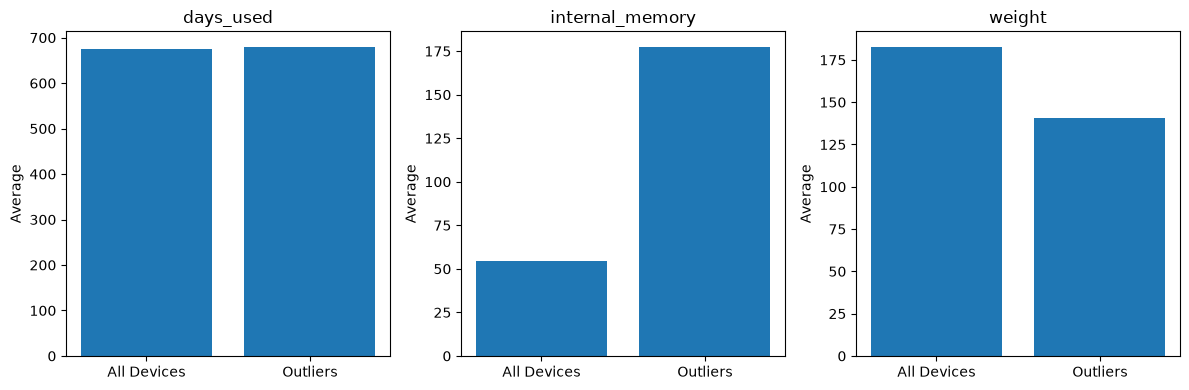

In [36]:
#Question 7c: Plot these comparions. You can choose the chart that you think will be more appropriate for visualization. (3 points)
columns = ['days_used', 'internal_memory', 'weight']

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, column in enumerate(columns):
    averages = [df[column].mean(), outliers[column].mean()]

    axes[i].bar(['All Devices', 'Outliers'], averages)
    axes[i].set_title(column)
    axes[i].set_ylabel('Average')

plt.tight_layout()
plt.show()
# The charts show that internal memory has the largest difference
# between the outliers and the entire dataset.
# Outlier devices have higher internal memory and lower weight.
# Days used is nearly identical between the two groups.

In [ ]:
#Continue Case 2 with stattsmodels

In [39]:
#Question 8: Create a multiple linear regression model using the following independent variables
#internal_memory, battery, weight, days_used, 5g_yes
#Your dependent variable is normalized_used_price
#Explain the coefficients properly (4 points)

import statsmodels.api as sm
print(df['5g'].value_counts(dropna=False))
# Convert 5G from yes/no into 1/0
df['5g_yes'] = (df['5g'] == 'yes').astype(int)

# Select the variables for our regression
columns = ['internal_memory', 'battery', 'weight',
           'days_used', '5g_yes', 'normalized_used_price']

# Remove rows with missing values in these variables
regression_data = df[columns].dropna()

# Independent variables
X = regression_data[['internal_memory', 'battery', 'weight',
                     'days_used', '5g_yes']]

# Dependent variable
y = regression_data['normalized_used_price']

# Add the constant (intercept)
X = sm.add_constant(X)

# Run the regression
model = sm.OLS(y, X).fit()

# Print the results
print(model.summary())
# The model has an R-squared of 0.424, meaning the predictors
# explain approximately 42.4% of the variation in used prices.

# Holding other variables constant:
# Internal memory has a positive coefficient (about 0.0004).
# Battery has a positive coefficient (about 0.0003).
# Weight has a negative coefficient (about -0.0002).
# Days used has a negative coefficient (about -0.0002).
# Phones with 5G have a predicted normalized used price
# 0.4406 higher than phones without 5G.

# Internal memory, battery, days used, and 5G are statistically
# significant at the 5% level. Weight is not (p = 0.080).


5g
no     3302
yes     152
Name: count, dtype: int64
                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.424
Model:                               OLS   Adj. R-squared:                  0.424
Method:                    Least Squares   F-statistic:                     506.0
Date:                   Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                           19:21:50   Log-Likelihood:                -2089.1
No. Observations:                   3437   AIC:                             4190.
Df Residuals:                       3431   BIC:                             4227.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

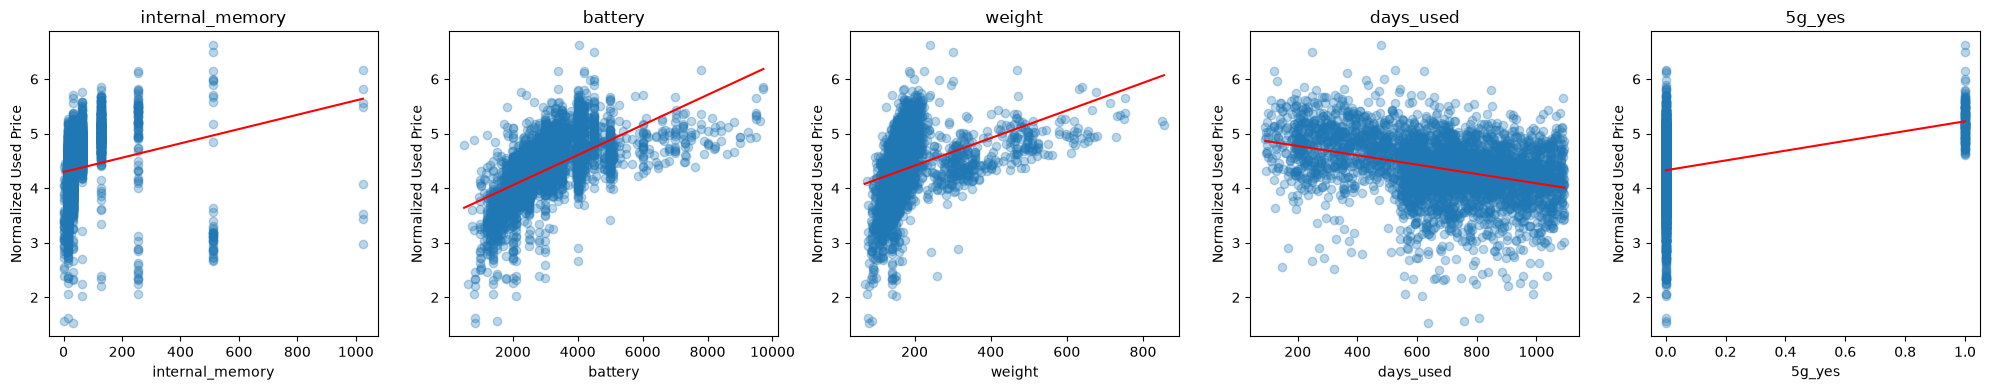

In [42]:
#Question 9:Develop scatterplots of each independent variable with the dependent variable with the regression lines.
# List of predictor variables (2 points)
predictors = ['internal_memory', 'battery', 'weight',
              'days_used', '5g_yes']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, column in enumerate(predictors):
    x = regression_data[column]
    y = regression_data['normalized_used_price']

    # Create scatterplot
    axes[i].scatter(x, y, alpha=0.3)

    # Calculate and draw regression line
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    axes[i].plot(x_line, y_line, color='red')

    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Normalized Used Price')

plt.tight_layout()
plt.show()
# Question 9 Interpretation

# Internal memory, battery, weight, and 5G show positive
# relationships with normalized used price.
# Days used shows a negative relationship with price.

# Weight has a positive relationship in the scatterplot,
# but a negative coefficient in the multiple regression.
# This difference occurs because the multiple regression
# controls for the other independent variables.